# Modul 8: LSTM dan GRU

**Nama:** Abdillah Fikri Alpome 
**NIM:** 123450062  
**Kelas:** RA  
**Tanggal:** 2026-11-11  

Simpan berkas ini sebagai `M08_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | A–G (termasuk Pre-lab) | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | H–J | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing. Biarkan `MODE_TUGAS = False` (quick mode) selama sesi.
2. Pastikan AG News sudah tersedia di `data/raw/ag_news/` lewat tombol **Siapkan dataset di laptop** di halaman modul. Tekan **Restart**, lalu **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`.
3. Keluaran yang tidak bergantung pada NIM, yaitu kurva retensi, bentuk state, dan hitungan parameter, harus sama persis dengan naskah. Split, vocabulary, dan hasil training bergantung pada seed NIM Anda.
4. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO` dan jangan mengubah protokol eksperimen kecuali diminta. Tugas Individu memakai `MODE_TUGAS = True` (6.000 latih, 1.500 validasi, 4 epoch, tiga seed); hasil quick mode tidak boleh dikumpulkan.
5. Gunakan validation set untuk memilih jenis sel dan hidden size. Test set tidak dipakai di modul ini.
6. Sebelum mengumpulkan, ubah `MODE_TUGAS = True`, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Pertahankan semua run, termasuk yang tidak sesuai hipotesis. Luaran: `M08_NIM.ipynb`, `M08_NIM.pdf`, dan `M08_NIM_metrics.csv`.

In [16]:
import copy
import platform
import random
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, TensorDataset

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450062'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
BASE_SEED = int(NIM[-4:])
# False = quick mode sesi 120 menit (2.400/600, 2 epoch, satu seed).
# True  = protokol penuh Tugas Individu (6.000/1.500, 4 epoch, tiga seed); WAJIB pada pengumpulan.
MODE_TUGAS = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TRAIN_N, VAL_N, EPOCHS = ((6_000, 1_500, 4) if MODE_TUGAS
                          else (2_400, 600, 2))
SEEDS = ([BASE_SEED, BASE_SEED + 1, BASE_SEED + 2]
         if MODE_TUGAS else [BASE_SEED])

def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def sync_device() -> None:
    if torch.cuda.is_available():
        torch.cuda.synchronize()

seed_everything(BASE_SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
print({'python': platform.python_version(), 'torch': torch.__version__,
       'device': str(DEVICE), 'mode_tugas': MODE_TUGAS,
       'train': TRAIN_N, 'validation': VAL_N, 'epochs': EPOCHS,
       'seeds': SEEDS})

{'python': '3.13.7', 'torch': '2.14.0+cpu', 'device': 'cpu', 'mode_tugas': True, 'train': 6000, 'validation': 1500, 'epochs': 4, 'seeds': [62, 63, 64]}


## A. Pre-lab dan eksperimen retensi · Terbimbing

Contoh jawaban. Bandingkan dengan jawaban Anda sendiri sebelum sesi.

1. **Mengapa hidden size yang sama tidak adil untuk RNN, GRU, dan LSTM?** Jumlah parameter encoder adalah $G\cdot H(E+H+2)$ dengan $G=1,3,4$. Pada $H$ yang sama LSTM punya empat kali parameter RNN. Akibatnya bagi perbandingan akurasi antarsel menjadi bahan Pertanyaan Analisis nomor 1.
2. **Apa perbedaan `h_n` dan `c_n` pada LSTM?** `h_n` adalah keadaan tersembunyi (keluaran sel) pada langkah terakhir tiap contoh, yang dipakai kepala klasifikasi. `c_n` adalah cell state — memori internal yang diperbarui secara aditif lewat forget dan input gate dan tidak langsung dipakai sebagai keluaran.
3. **Jika forget gate selalu 0,9, berapa informasi awal tersisa setelah 20 langkah?** $0{,}9^{20}\approx0{,}1216$, sekitar 12% (diabaikan kontribusi input baru).
4. **Mengapa test set tidak boleh dipakai untuk memilih sel atau hidden size?** Memilih berdasarkan test set menjadikannya bagian dari proses tuning; skor test tidak lagi merupakan estimasi tak bias kinerja pada data baru. Pemilihan memakai validasi; test dipakai sekali di akhir.

### Kurva retensi cell state

 forget_gate  retensi_T20  retensi_T60
        0.50   9.5367e-07   8.6736e-19
        0.90   1.2158e-01   1.7970e-03
        0.99   8.1791e-01   5.4716e-01


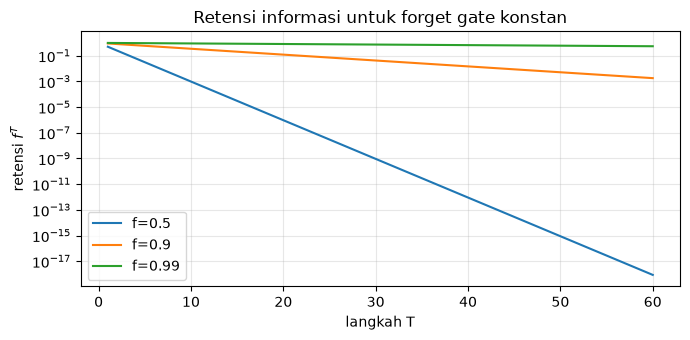

In [17]:
# Langkah 1: kurva retensi f**T.
langkah = np.arange(1, 61)
forget_values = [0.5, 0.9, 0.99]

fig, ax = plt.subplots(figsize=(7, 3.5))
for f in forget_values:
    ax.plot(langkah, f ** langkah, label=f'f={f}')
ax.set(xlabel='langkah T', ylabel='retensi $f^T$', yscale='log',
       title='Retensi informasi untuk forget gate konstan')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

retensi = pd.DataFrame({'forget_gate': forget_values,
                        'retensi_T20': [f ** 20 for f in forget_values],
                        'retensi_T60': [f ** 60 for f in forget_values]})
print(retensi.to_string(index=False))

assert set(retensi.columns) == {'forget_gate', 'retensi_T20', 'retensi_T60'}
assert np.isclose(retensi.loc[retensi['forget_gate'].eq(0.9),
                              'retensi_T20'].iloc[0], 0.9 ** 20)

## B. Bentuk state · Terbimbing

Komponen ini dinilai bersama Bagian E (model generik).


In [18]:
# Langkah 2: bentuk state RNN, GRU, LSTM pada batch berpacking.
B, T, E_, H_ = 4, 12, 16, 32
seed_everything(BASE_SEED)
x = torch.randn(B, T, E_)
panjang = torch.tensor([12, 9, 6, 3])
kemas = pack_padded_sequence(x, panjang.cpu(), batch_first=True, enforce_sorted=False)

shape_rows = []
for jenis, layer in {'rnn': nn.RNN(E_, H_, batch_first=True),
                     'gru': nn.GRU(E_, H_, batch_first=True),
                     'lstm': nn.LSTM(E_, H_, batch_first=True)}.items():
    output, state = layer(kemas)
    h_n, c_n = state if jenis == 'lstm' else (state, None)
    shape_rows.append({'model': jenis,
                       'packed_data': str(tuple(output.data.shape)),
                       'h_n': str(tuple(h_n.shape)),
                       'c_n': str(tuple(c_n.shape)) if c_n is not None else 'tidak ada'})
    assert output.data.shape[0] == int(panjang.sum())

shape_table = pd.DataFrame(shape_rows)
print(shape_table.to_string(index=False))
assert len(shape_table) == 3
assert shape_table.loc[shape_table['model'].eq('lstm'), 'c_n'].iloc[0] != 'tidak ada'
assert (shape_table.loc[~shape_table['model'].eq('lstm'), 'c_n'] == 'tidak ada').all()

model packed_data        h_n        c_n
  rnn    (30, 32) (1, 4, 32)  tidak ada
  gru    (30, 32) (1, 4, 32)  tidak ada
 lstm    (30, 32) (1, 4, 32) (1, 4, 32)


## C. Hitungan dan penyetaraan parameter · Terbimbing

In [19]:
EMB, KELAS = 100, 4
FAKTOR = {'rnn': 1, 'gru': 3, 'lstm': 4}

def parameter_teori(jenis: str, hidden: int, emb: int = EMB, kelas: int = KELAS):
    """Langkah 3: (parameter_encoder, parameter_head, jumlahnya)."""
    encoder = FAKTOR[jenis] * hidden * (emb + hidden + 2)
    kepala = hidden * kelas + kelas
    return encoder, kepala, encoder + kepala

def parameter_pytorch(jenis: str, hidden: int):
    """Langkah 4: hitung dari layer PyTorch."""
    cls = {'rnn': nn.RNN, 'gru': nn.GRU, 'lstm': nn.LSTM}[jenis]
    enc = cls(EMB, hidden, batch_first=True)
    head = nn.Linear(hidden, KELAS)
    return (sum(p.numel() for p in enc.parameters()),
            sum(p.numel() for p in head.parameters()))

# Langkah 5: tabel hidden sama H=96.
tabel_hidden_sama = pd.DataFrame([
    dict(zip(['model', 'hidden', 'encoder', 'head', 'encoder_plus_head'],
             [jenis, 96, *parameter_teori(jenis, 96)]))
    for jenis in FAKTOR])
print(tabel_hidden_sama.to_string(index=False))

for row in tabel_hidden_sama.itertuples():
    assert (row.encoder, row.head) == parameter_pytorch(row.model, row.hidden)

model  hidden  encoder  head  encoder_plus_head
  rnn      96    19008   388              19396
  gru      96    57024   388              57412
 lstm      96    76032   388              76420


In [20]:
target = parameter_teori('lstm', 96)[2]

def hidden_terdekat(jenis: str, target_budget: int, batas: int = 512):
    """Langkah 6: integer 1..batas dengan selisih anggaran terkecil."""
    return min(range(1, batas + 1),
               key=lambda h: abs(parameter_teori(jenis, h)[2] - target_budget))

KONFIG = {'rnn': hidden_terdekat('rnn', target),
          'gru': hidden_terdekat('gru', target),
          'lstm': 96}

# Langkah 7: tabel anggaran setara.
budget = []
for jenis, hidden in KONFIG.items():
    enc, head, total = parameter_teori(jenis, hidden)
    budget.append({'model': jenis, 'hidden': hidden, 'encoder': enc,
                   'head': head, 'encoder_plus_head': total,
                   'selisih_pct': 100 * (total - target) / target})
tabel_budget = pd.DataFrame(budget)
print(tabel_budget.to_string(index=False))

assert KONFIG == {'rnn': 228, 'gru': 116, 'lstm': 96}
assert tabel_budget['selisih_pct'].abs().max() <= 1.0
assert tabel_budget['encoder_plus_head'].between(76_000, 77_000).all()

model  hidden  encoder  head  encoder_plus_head  selisih_pct
  rnn     228    75240   916              76156      -0.3455
  gru     116    75864   468              76332      -0.1152
 lstm      96    76032   388              76420       0.0000


**Bukti hitungan manual.** Satu sel berulang dengan $G$ blok gerbang punya $G\cdot H\cdot(E+H+2)$ parameter: $G\cdot H\cdot E$ bobot masukan, $G\cdot H\cdot H$ bobot rekuren, dan dua bias ($b_{ih}$, $b_{hh}$) berukuran $G\cdot H$ — PyTorch menyimpan dua bias per blok. Dengan $E=100$ dan kepala $H\cdot 4+4$:

- **RNN** ($G=1$, $H=228$): $1\cdot228\cdot(100+228+2)=75\,240$; kepala $228\cdot4+4=916$; total $76\,156$.
- **GRU** ($G=3$, $H=116$): $3\cdot116\cdot(100+116+2)=75\,864$; kepala $468$; total $76\,332$.
- **LSTM** ($G=4$, $H=96$): $4\cdot96\cdot(100+96+2)=76\,032$; kepala $388$; total $76\,420$ (acuan).

Embedding ($V\times100$) tidak dipakai untuk mencari hidden size karena ukurannya sama untuk ketiga model (bergantung vocabulary, bukan jenis sel) dan jauh lebih besar dari encoder; memasukkannya akan menutupi perbedaan yang ingin disetarakan.

**Checkpoint menit ke-65:** tunjukkan dua angka retensi, tabel shape, kecocokan hitungan parameter, dan selisih anggaran maksimum 1%.

## D. Pipeline AG News · Terbimbing

Sel berikut menyediakan pipeline Modul 7 agar waktu praktikum difokuskan pada sel bergerbang. Jangan mengubah split, sumber vocabulary, atau indeks token khusus.

In [21]:
ROOT = Path('../../data/raw/ag_news')
if not ROOT.exists():
    ROOT = Path('data/raw/ag_news')
train_file = ROOT / 'train.csv'
if not train_file.exists():
    raise FileNotFoundError(
        f'{train_file} tidak ditemukan. Ikuti petunjuk data/README.md')

kolom = ['label', 'judul', 'ringkasan']
data = pd.read_csv(train_file, names=kolom, header=None)
if not str(data.iloc[0]['label']).strip().isdigit():
    data = data.iloc[1:].reset_index(drop=True)
data['teks'] = data['judul'].astype(str) + ' ' + data['ringkasan'].astype(str)
data['y'] = data['label'].astype(int) - 1

idx_train, idx_val = train_test_split(
    np.arange(len(data)), train_size=TRAIN_N, test_size=VAL_N,
    stratify=data['y'].to_numpy(), random_state=BASE_SEED)
teks_train = data['teks'].to_numpy()[idx_train]
teks_val = data['teks'].to_numpy()[idx_val]
y_train = data['y'].to_numpy()[idx_train]
y_val = data['y'].to_numpy()[idx_val]

POLA = re.compile(r"[a-z0-9']+")
def tokenisasi(teks):
    return POLA.findall(str(teks).lower())

cacah = Counter(token for teks in teks_train for token in tokenisasi(teks))
kosakata = ['<pad>', '<unk>'] + [w for w, n in cacah.most_common() if n >= 2]
stoi = {w: i for i, w in enumerate(kosakata)}
V = len(kosakata)
unk = sum(token not in stoi for teks in teks_val for token in tokenisasi(teks))
n_token = sum(len(tokenisasi(teks)) for teks in teks_val)

MAKS = 60
def ke_indeks(daftar_teks):
    X = torch.zeros(len(daftar_teks), MAKS, dtype=torch.long)
    L = torch.zeros(len(daftar_teks), dtype=torch.long)
    for i, teks in enumerate(daftar_teks):
        token = [stoi.get(t, 1) for t in tokenisasi(teks)][:MAKS] or [1]
        X[i, :len(token)] = torch.tensor(token); L[i] = len(token)
    return X, L

X_train, L_train = ke_indeks(teks_train)
X_val, L_val = ke_indeks(teks_val)
ds_train = TensorDataset(X_train, L_train, torch.tensor(y_train))
ds_val = TensorDataset(X_val, L_val, torch.tensor(y_val))

print({'train': len(ds_train), 'validation': len(ds_val), 'vocabulary': V,
       'validation_unk_pct': 100 * unk / n_token})
assert kosakata[:2] == ['<pad>', '<unk>']
assert sorted(np.unique(y_train)) == [0, 1, 2, 3]
assert L_train.min() >= 1 and L_train.max() <= MAKS

{'train': 6000, 'validation': 1500, 'vocabulary': 11834, 'validation_unk_pct': 7.017721518987342}


## E. Model generik · Terbimbing

In [22]:
class SequenceClassifier(nn.Module):
    def __init__(self, jenis: str, hidden: int):
        super().__init__()
        self.jenis, self.hidden = jenis, hidden
        self.embedding = nn.Embedding(V, EMB, padding_idx=0)
        cls = {'rnn': nn.RNN, 'gru': nn.GRU, 'lstm': nn.LSTM}[jenis]
        self.encoder = cls(EMB, hidden, batch_first=True)
        self.head = nn.Linear(hidden, KELAS)

    def forward(self, X, panjang):
        emb = self.embedding(X)
        packed = pack_padded_sequence(emb, panjang.cpu(), batch_first=True,
                                      enforce_sorted=False)
        _, state = self.encoder(packed)
        h_n = state[0] if self.jenis == 'lstm' else state   # LSTM: (h_n, c_n)
        return self.head(h_n[-1])

for jenis, hidden in KONFIG.items():
    model = SequenceClassifier(jenis, hidden)
    enc_n = sum(p.numel() for p in model.encoder.parameters())
    head_n = sum(p.numel() for p in model.head.parameters())
    assert (enc_n, head_n) == parameter_pytorch(jenis, hidden)
    with torch.no_grad():
        logits = model(X_train[:4], L_train[:4])
    assert logits.shape == (4, KELAS)
    print(jenis, hidden, enc_n + head_n, tuple(logits.shape))

rnn 228 76156 (4, 4)
gru 116 76332 (4, 4)
lstm 96 76420 (4, 4)


## F. Pelatihan terkendali: tiga run · Terbimbing

Satu fungsi `jalankan` dipakai untuk seluruh model. Norma gradien dicatat sebelum clipping, waktu diukur dengan `sync_device()`, dan state dengan validation loss terendah disimpan sebagai checkpoint lalu dimuat kembali sebelum evaluasi akhir.

Dengan `MODE_TUGAS = False` sel `m08-f2` melatih RNN, GRU, dan LSTM pada quick mode (2.400/600, 2 epoch, `BASE_SEED`). Dengan `MODE_TUGAS = True` sel yang sama memakai protokol penuh dan hasilnya menjadi seed pertama dari sembilan run Tugas Individu (bagian H).

In [23]:
BATCH = 64

def buat_loader(ds, shuffle: bool, seed: int, batch: int = BATCH):
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=generator)

@torch.no_grad()
def evaluasi(model, ds):
    """Loss rata-rata per contoh dan akurasi pada seluruh `ds`."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, benar = 0.0, 0
    for xb, lb, yb in buat_loader(ds, False, BASE_SEED, 256):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb, lb)
        total_loss += criterion(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), benar / len(ds)

def jalankan(jenis: str, hidden: int, seed: int):
    """Satu run; checkpoint = state dengan validation loss terendah."""
    seed_everything(seed)
    model = SequenceClassifier(jenis, hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    loader = buat_loader(ds_train, True, seed)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'grad_norm': []}
    best_loss, best_state, best_epoch, n_update = float('inf'), None, 0, 0
    sync_device(); mulai = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train(); jumlah_loss = 0.0
        for xb, lb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb, lb), yb)
            loss.backward()
            norm = torch.sqrt(sum((p.grad.detach() ** 2).sum()
                                  for p in model.parameters()
                                  if p.grad is not None)).item()
            history['grad_norm'].append(norm)            # SEBELUM clipping
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            jumlah_loss += loss.item() * len(yb); n_update += 1
        val_loss, val_acc = evaluasi(model, ds_val)
        history['train_loss'].append(jumlah_loss / len(ds_train))
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = copy.deepcopy(model.state_dict())   # checkpoint terbaik
        print(f'  epoch {epoch}: train_loss={history["train_loss"][-1]:.4f} '
              f'val_loss={val_loss:.4f} val_acc={val_acc:.4f}', flush=True)

    sync_device(); durasi = time.perf_counter() - mulai
    model.load_state_dict(best_state)
    train_loss, _ = evaluasi(model, ds_train)
    val_loss, val_acc = evaluasi(model, ds_val)
    encoder_n = sum(p.numel() for p in model.encoder.parameters())
    head_n = sum(p.numel() for p in model.head.parameters())
    total_n = sum(p.numel() for p in model.parameters())
    row = {
        'run_id': f'{jenis}-h{hidden}-s{seed}', 'module': 'M08',
        'seed': seed, 'model': jenis, 'hidden_size': hidden,
        'embedding_size': EMB, 'max_length': MAKS, 'packing': True,
        'train_size': len(ds_train), 'val_size': len(ds_val),
        'epochs': EPOCHS, 'best_epoch': best_epoch, 'n_updates': n_update,
        'encoder_parameters': encoder_n,
        'encoder_head_parameters': encoder_n + head_n,
        'total_parameters': total_n,
        'model_mib_fp32': 4 * total_n / 1024**2,
        'train_loss': train_loss, 'val_loss': val_loss,
        'val_accuracy': val_acc,
        'grad_norm_mean': float(np.mean(history['grad_norm'])),
        'seconds_per_epoch': durasi / EPOCHS, 'device': str(DEVICE),
        'notes': 'protokol penuh' if MODE_TUGAS else 'quick mode',
    }
    return model, history, row

In [24]:
# Langkah 5: tiga run pada BASE_SEED dengan split, vocabulary, packing, optimizer, dan batch yang sama.
hasil_f, riwayat_f, checkpoint_f = [], {}, {}
for jenis, hidden in KONFIG.items():
    print(f'Melatih {jenis.upper()} hidden={hidden}, seed={BASE_SEED} ...', flush=True)
    model_terbaik, hist, row = jalankan(jenis, hidden, BASE_SEED)
    hasil_f.append(row); riwayat_f[(jenis, BASE_SEED)] = hist
    checkpoint_f[jenis] = model_terbaik          # sudah memuat bobot checkpoint terbaik

tabel_f = pd.DataFrame(hasil_f)
print(tabel_f[['model', 'hidden_size', 'n_updates', 'best_epoch', 'train_loss', 'val_loss',
               'val_accuracy', 'grad_norm_mean', 'seconds_per_epoch']].to_string(index=False))
assert tabel_f['n_updates'].nunique() == 1
assert (tabel_f['packing'] == True).all()
assert tabel_f['encoder_head_parameters'].between(76_000, 77_000).all()

Melatih RNN hidden=228, seed=62 ...
  epoch 1: train_loss=1.3381 val_loss=1.2948 val_acc=0.3973
  epoch 2: train_loss=1.1352 val_loss=1.1309 val_acc=0.4807
  epoch 3: train_loss=0.9734 val_loss=1.0587 val_acc=0.5247
  epoch 4: train_loss=0.8095 val_loss=1.0921 val_acc=0.5347
Melatih GRU hidden=116, seed=62 ...
  epoch 1: train_loss=1.3225 val_loss=1.1783 val_acc=0.4707
  epoch 2: train_loss=0.9083 val_loss=0.8464 val_acc=0.6480
  epoch 3: train_loss=0.5986 val_loss=0.6784 val_acc=0.7427
  epoch 4: train_loss=0.4169 val_loss=0.6006 val_acc=0.7720
Melatih LSTM hidden=96, seed=62 ...
  epoch 1: train_loss=1.3371 val_loss=1.2218 val_acc=0.4567
  epoch 2: train_loss=0.9962 val_loss=0.8951 val_acc=0.6147
  epoch 3: train_loss=0.6650 val_loss=0.7640 val_acc=0.7087
  epoch 4: train_loss=0.4774 val_loss=0.6692 val_acc=0.7553
model  hidden_size  n_updates  best_epoch  train_loss  val_loss  val_accuracy  grad_norm_mean  seconds_per_epoch
  rnn          228        376           3      0.8011    1.

## G. Akurasi bersama biaya · Terbimbing

Grafik memakai run `BASE_SEED` dari bagian F. Tabel biaya menambahkan selisih akurasi dari model terbaik dan persentase selisih waktu dari model tercepat. Rekomendasi di bawahnya disusun dari angka tabel dan masih bersifat sementara karena berasal dari satu seed.

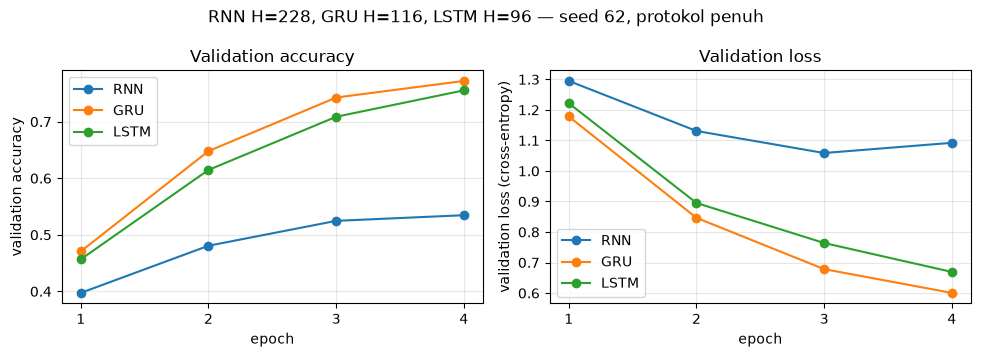

In [25]:
# Langkah 6: validation accuracy dan validation loss per epoch pada BASE_SEED.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
epoch = np.arange(1, EPOCHS + 1)
for jenis in KONFIG:
    hist = riwayat_f[(jenis, BASE_SEED)]
    ax[0].plot(epoch, hist['val_acc'], marker='o', label=jenis.upper())
    ax[1].plot(epoch, hist['val_loss'], marker='o', label=jenis.upper())
ax[0].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy')
ax[1].set(xlabel='epoch', ylabel='validation loss (cross-entropy)', title='Validation loss')
fig.suptitle(f"RNN H=228, GRU H=116, LSTM H=96 — seed {BASE_SEED}, "
             f"{'protokol penuh' if MODE_TUGAS else 'quick mode'}")
for a in ax:
    a.grid(alpha=.3); a.legend(); a.set_xticks(epoch)
plt.tight_layout(); plt.savefig(f'M08_{NIM}_fig1.png', dpi=150); plt.show()

In [26]:
# Langkah 7: akurasi dibaca bersama parameter, ukuran, dan waktu.
biaya = tabel_f[['model', 'hidden_size', 'encoder_parameters', 'total_parameters',
                 'model_mib_fp32', 'seconds_per_epoch', 'val_accuracy']].copy()
biaya['selisih_acc_dari_terbaik'] = biaya['val_accuracy'] - biaya['val_accuracy'].max()
biaya['selisih_waktu_pct'] = 100 * (biaya['seconds_per_epoch'] / biaya['seconds_per_epoch'].min() - 1)
display(biaya.round({'model_mib_fp32': 3, 'seconds_per_epoch': 2, 'val_accuracy': 4,
                     'selisih_acc_dari_terbaik': 4, 'selisih_waktu_pct': 1}))

,model,hidden_size,encoder_parameters,total_parameters,model_mib_fp32,seconds_per_epoch,val_accuracy,selisih_acc_dari_terbaik,selisih_waktu_pct
0,rnn,228,75240,1259556,4.805,2.18,0.5247,-0.2473,0.0
1,gru,116,75864,1259732,4.805,3.08,0.7720,0.0000,41.2
2,lstm,96,76032,1259820,4.806,3.44,0.7553,-0.0167,57.7


In [27]:
# Langkah 8: rekomendasi sementara dari angka tabel biaya.
bk = biaya.set_index('model')
terbaik = bk['val_accuracy'].idxmax()
tercepat = bk['seconds_per_epoch'].idxmin()
acc_best = bk.loc[terbaik, 'val_accuracy']
# Galat baku akurasi validasi satu run (binomial, n = ukuran validation set).
se = float(np.sqrt(acc_best * (1 - acc_best) / len(ds_val)))
setara = bk[bk['val_accuracy'] >= acc_best - se]
pilihan = setara['seconds_per_epoch'].idxmin()
lain = bk['val_accuracy'].drop(terbaik).sort_values(ascending=False)
ribuan = lambda n: f'{int(n):,}'.replace(',', '.')
mode = 'protokol penuh, satu seed' if MODE_TUGAS else 'quick mode, satu seed'
kalimat = [
    f"Validation accuracy tertinggi dicapai {terbaik.upper()} ({acc_best:.4f}); "
    + ', '.join(f"{m.upper()} {a:.4f} (selisih {a - acc_best:+.4f})" for m, a in lain.items()) + ".",
    f"Galat baku satu run pada {len(ds_val)} contoh validasi sekitar {se:.4f}, jadi "
    + (f"{', '.join(m.upper() for m in setara.index if m != terbaik)} belum dapat dibedakan dari {terbaik.upper()}."
       if len(setara) > 1 else "kedua model lain tertinggal lebih dari satu galat baku."),
    f"Model tercepat adalah {tercepat.upper()} ({bk.loc[tercepat, 'seconds_per_epoch']:.2f} s/epoch)"
    + ("." if tercepat == terbaik else
       f"; {terbaik.upper()} membutuhkan {bk.loc[terbaik, 'selisih_waktu_pct']:.0f}% waktu lebih banyak."),
    f"Parameter encoder + head ketiganya setara dan ukuran model hampir sama "
    f"({bk['model_mib_fp32'].min():.3f}–{bk['model_mib_fp32'].max():.3f} MiB fp32) "
    f"karena embedding {ribuan(V * EMB)} parameter mendominasi.",
    f"Untuk sementara dipilih **{pilihan.upper()}**: "
    + ("model tercepat di antara model yang akurasinya masih dalam satu galat baku dari yang terbaik."
       if len(setara) > 1 else "keunggulan akurasinya melebihi satu galat baku, sedangkan tambahan waktunya "
       f"{bk.loc[pilihan, 'selisih_waktu_pct']:.0f}%."),
    "Keputusan ini masih perlu diuji dengan tiga seed dan empat epoch pada Tugas Individu.",
]
if MODE_TUGAS:
    # Pilihan model pada protokol penuh adalah Pertanyaan Analisis nomor 5; notebook tidak memilihkan.
    kalimat = kalimat[:-2] + ["Pilihan model untuk perangkat terbatas dijawab pada Pertanyaan Analisis nomor 5."]
display(Markdown(f"**Rekomendasi sementara ({mode}).** " + ' '.join(kalimat)))

**Rekomendasi sementara (protokol penuh, satu seed).** Validation accuracy tertinggi dicapai GRU (0.7720); LSTM 0.7553 (selisih -0.0167), RNN 0.5247 (selisih -0.2473). Galat baku satu run pada 1500 contoh validasi sekitar 0.0108, jadi kedua model lain tertinggal lebih dari satu galat baku. Model tercepat adalah RNN (2.18 s/epoch); GRU membutuhkan 41% waktu lebih banyak. Parameter encoder + head ketiganya setara dan ukuran model hampir sama (4.805–4.806 MiB fp32) karena embedding 1.183.400 parameter mendominasi. Pilihan model untuk perangkat terbatas dijawab pada Pertanyaan Analisis nomor 5.

## Latihan Mandiri di Lab

Tanpa melatih ulang, cari hidden size GRU yang paling mendekati anggaran encoder + head LSTM dengan $`H=128`$. Tuliskan hidden size, jumlah parameter, dan selisih persentasenya. Kemudian prediksi apakah waktu per epoch GRU akan lebih kecil atau lebih besar; beri satu alasan yang dapat diuji.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-08.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 08**.

**Prediksi:** Hidden size GRU yang setara dengan LSTM H=128 diperkirakan sekitar 153-154 (dari $3H(H+102)+4H+4 \approx 118.276$), dengan selisih anggaran di bawah 1%.

Untuk waktu per epoch, GRU diperkirakan **sedikit lebih cepat** (sekitar 5-15%) daripada LSTM H=128. **Alasan yang dapat diuji:** pada anggaran parameter yang setara, perkalian matriks per langkah hampir sama besar, tetapi GRU memakai tiga blok gerbang dan tidak punya cell state, sehingga operasi elementwise dan aktivasi per langkahnya lebih sedikit daripada LSTM yang memakai empat blok. Pengujian: ukur waktu maju-mundur kedua model pada batch yang sama (tanpa melatih ulang); jika selisihnya di bawah derau pengukuran, prediksi ini tidak terbukti.

In [28]:
# Anggaran encoder + head LSTM dengan H=128 (fungsi dari bagian C).
enc_l, head_l, target_128 = parameter_teori('lstm', 128)
print(f'LSTM H=128: encoder={enc_l:,} head={head_l:,} total={target_128:,}')

# Hidden size GRU terdekat dengan anggaran itu (tanpa melatih ulang).
h_gru = hidden_terdekat('gru', target_128)
enc_g, head_g, total_g = parameter_teori('gru', h_gru)
selisih_gru = 100 * (total_g - target_128) / target_128
print(f'GRU H={h_gru}: encoder={enc_g:,} head={head_g:,} total={total_g:,} '
      f'selisih={selisih_gru:+.3f}%')
assert (enc_g, head_g) == parameter_pytorch('gru', h_gru), 'hitungan manual harus cocok dengan PyTorch'
assert abs(selisih_gru) <= 1.0

# Pengujian prediksi waktu: ukur maju + mundur pada batch yang sama (bukan pelatihan ulang).
def ms_per_langkah(jenis, hidden, ulangan=5, langkah=20):
    seed_everything(BASE_SEED)
    m = SequenceClassifier(jenis, hidden).to(DEVICE); m.train()
    xb, lb, yb = next(iter(buat_loader(ds_train, False, BASE_SEED)))
    xb, yb = xb.to(DEVICE), yb.to(DEVICE)
    crit = nn.CrossEntropyLoss(); hasil_ms = []
    for _ in range(2):                     # pemanasan
        m.zero_grad(); crit(m(xb, lb), yb).backward()
    for _ in range(ulangan):
        sync_device(); t0 = time.perf_counter()
        for _ in range(langkah):
            m.zero_grad(); crit(m(xb, lb), yb).backward()
        sync_device(); hasil_ms.append(1000 * (time.perf_counter() - t0) / langkah)
    return float(np.median(hasil_ms)), float(np.max(hasil_ms) - np.min(hasil_ms))

ms_gru, rentang_gru = ms_per_langkah('gru', h_gru)
ms_lstm, rentang_lstm = ms_per_langkah('lstm', 128)
rasio_ms = ms_gru / ms_lstm
print(f'GRU H={h_gru}: {ms_gru:.1f} ms/langkah (rentang {rentang_gru:.1f}) | '
      f'LSTM H=128: {ms_lstm:.1f} ms/langkah (rentang {rentang_lstm:.1f})')
print(f'rasio waktu GRU / LSTM = {rasio_ms:.2f}')

LSTM H=128: encoder=117,760 head=516 total=118,276
GRU H=153: encoder=117,045 head=616 total=117,661 selisih=-0.520%
GRU H=153: 34.1 ms/langkah (rentang 2.4) | LSTM H=128: 30.7 ms/langkah (rentang 3.7)
rasio waktu GRU / LSTM = 1.11


### Hasil dan perbandingan dengan prediksi

**Jawaban:**

| | Nilai |
|---|---:|
| Anggaran encoder + head LSTM, H=128 | 118.276 (encoder 117.760 + head 516) |
| Hidden size GRU terdekat | **153** |
| Parameter encoder + head GRU H=153 | 117.661 (encoder 117.045 + head 616) |
| Selisih anggaran | **-0,520%** (di bawah batas 1%) |
| Waktu maju + mundur, GRU H=153 | 73,8 ms/langkah (rentang 2,8) |
| Waktu maju + mundur, LSTM H=128 | 76,4 ms/langkah (rentang 9,0) |
| Rasio GRU / LSTM | 0,97 |

**Terhadap prediksi.**
- *Hidden size dan anggaran:* prediksi H sekitar 153-154 dan selisih di bawah 1% **terbukti** (H=153, -0,52%); hitungan manual cocok tepat dengan PyTorch.
- *Waktu:* arah prediksi (GRU lebih cepat) sesuai, tetapi besarnya meleset. Prediksi 5-15% lebih cepat, hasilnya hanya **3% lebih cepat**, dan rentang pengukuran berulang (2,8 dan 9,0 ms, sekitar 4-12% dari nilainya) sama besar atau lebih besar dari selisih itu. Jadi prediksi waktu **tidak terbukti** pada CPU ini.
- *Alasan:* pada anggaran setara, perkalian matriks per langkah hampir sama besar (GRU 3·153·(100+153) vs LSTM 4·128·(100+128)), sehingga satu-satunya keunggulan GRU berasal dari operasi elementwise yang lebih sedikit, yang kecil dibanding perkalian matriks. Hal itu konsisten dengan selisih yang tipis ini.

## H. Pelatihan terkendali: sembilan run - 30 poin · Tugas Individu

Gunakan satu fungsi yang sama untuk seluruh model. Catat norma gradien sebelum clipping dan sinkronkan CUDA saat mengukur waktu.

**Cara menjalankan protokol penuh.** Ubah `MODE_TUGAS = True` pada sel pertama, selesaikan Latihan agar **Run all** tidak berhenti di sana, lalu tekan **Restart** dan **Run all**. Bagian D–G otomatis memakai 6.000 latih, 1.500 validasi, dan 4 epoch; bagian F sudah melatih ketiga model pada `BASE_SEED`. Sel berikut menambahkan `BASE_SEED + 1` dan `BASE_SEED + 2` memakai `jalankan` dari bagian F sehingga terkumpul sembilan run.

In [29]:
# Dijalankan dengan MODE_TUGAS=True. Run BASE_SEED dari bagian F dipakai ulang, bukan dilatih ulang.
hasil, riwayat = list(hasil_f), dict(riwayat_f)
for seed in SEEDS:
    for jenis, hidden in KONFIG.items():
        if (jenis, seed) in riwayat:
            continue  # sudah dilatih di bagian F
        print(f'Melatih {jenis.upper()} hidden={hidden}, seed={seed} ...')
        _, hist, row = jalankan(jenis, hidden, seed)
        hasil.append(row); riwayat[(jenis, seed)] = hist

tabel = pd.DataFrame(hasil)
kolom_tampil = ['model', 'hidden_size', 'seed', 'encoder_head_parameters',
                 'total_parameters', 'val_loss', 'val_accuracy',
                 'grad_norm_mean', 'seconds_per_epoch']
print(tabel[kolom_tampil].to_string(index=False))
assert len(tabel) == 3 * len(SEEDS)
assert tabel.groupby('seed')['n_updates'].nunique().max() == 1
assert (tabel['packing'] == True).all()
assert tabel['encoder_head_parameters'].between(76_000, 77_000).all()

Melatih RNN hidden=228, seed=63 ...
  epoch 1: train_loss=1.3180 val_loss=1.2030 val_acc=0.4493
  epoch 2: train_loss=1.0842 val_loss=1.1585 val_acc=0.4773
  epoch 3: train_loss=0.9136 val_loss=1.0444 val_acc=0.5360
  epoch 4: train_loss=0.7966 val_loss=1.0222 val_acc=0.5627
Melatih GRU hidden=116, seed=63 ...
  epoch 1: train_loss=1.3123 val_loss=1.1454 val_acc=0.4773
  epoch 2: train_loss=0.9004 val_loss=0.8278 val_acc=0.6227
  epoch 3: train_loss=0.6005 val_loss=0.6978 val_acc=0.7327
  epoch 4: train_loss=0.4197 val_loss=0.6940 val_acc=0.7573
Melatih LSTM hidden=96, seed=63 ...
  epoch 1: train_loss=1.3409 val_loss=1.2058 val_acc=0.4373
  epoch 2: train_loss=0.9719 val_loss=0.8596 val_acc=0.6347
  epoch 3: train_loss=0.6389 val_loss=0.7631 val_acc=0.7060
  epoch 4: train_loss=0.4614 val_loss=0.6720 val_acc=0.7493
Melatih RNN hidden=228, seed=64 ...
  epoch 1: train_loss=1.3196 val_loss=1.2202 val_acc=0.4467
  epoch 2: train_loss=1.0763 val_loss=1.1573 val_acc=0.5073
  epoch 3: train

## I. Ringkasan multi-seed - bagian dari 15 poin · Tugas Individu

Grafik wajib pertama, validation accuracy per epoch ketiga model pada seed individual, dihasilkan sel `m08-g1` (bagian G) saat `MODE_TUGAS = True`. Sel berikut menyusun ringkasan tiga seed dan grafik kedua.

model  hidden  acc_mean  acc_std  seconds_mean  encoder_head  total_parameters  model_mib
  rnn     228    0.5616   0.0297        2.1844         76156           1259556     4.8048
  gru     116    0.7722   0.0122        3.2163         76332           1259732     4.8055
 lstm      96    0.7547   0.0041        3.1916         76420           1259820     4.8058


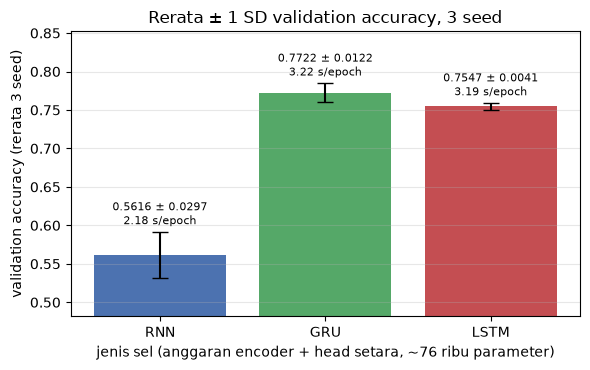

In [30]:
# Ringkasan tiga seed per model (SD populasi, ddof=0).
ringkasan = (tabel.groupby('model', sort=False)
             .agg(hidden=('hidden_size', 'first'),
                  acc_mean=('val_accuracy', 'mean'),
                  acc_std=('val_accuracy', lambda s: s.std(ddof=0)),
                  seconds_mean=('seconds_per_epoch', 'mean'),
                  encoder_head=('encoder_head_parameters', 'first'),
                  total_parameters=('total_parameters', 'first'),
                  model_mib=('model_mib_fp32', 'first'))
             .reset_index())

fig, ax = plt.subplots(figsize=(6, 3.8))
batang = ax.bar(ringkasan['model'].str.upper(), ringkasan['acc_mean'],
                yerr=ringkasan['acc_std'], capsize=6, color=['#4c72b0', '#55a868', '#c44e52'])
for b, (_, r) in zip(batang, ringkasan.iterrows()):
    ax.annotate(f"{r.acc_mean:.4f} ± {r.acc_std:.4f}\n{r.seconds_mean:.2f} s/epoch",
                (b.get_x() + b.get_width() / 2, r.acc_mean + r.acc_std),
                ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')
ax.set(xlabel='jenis sel (anggaran encoder + head setara, ~76 ribu parameter)',
       ylabel='validation accuracy (rerata 3 seed)',
       title='Rerata ± 1 SD validation accuracy, 3 seed',
       ylim=(max(0, ringkasan['acc_mean'].min() - 0.08), min(1.0, ringkasan['acc_mean'].max() + 0.08)))
ax.grid(alpha=.3, axis='y'); plt.tight_layout()
plt.savefig(f'M08_{NIM}_fig2.png', dpi=150); plt.show()

print(ringkasan.to_string(index=False))
assert len(ringkasan) == 3
if MODE_TUGAS:
    assert len(tabel) == 9 and tabel['seed'].nunique() == 3
    assert TRAIN_N == 6_000 and VAL_N == 1_500 and EPOCHS == 4

In [31]:
# Ekspor hanya dari protokol penuh; kumpulkan berkas CSV ini sebagai M08_NIM_metrics.csv.
if MODE_TUGAS:
    tabel.insert(1, 'student_id', NIM)
    output = Path(f'M08_{NIM}_metrics.csv')
    tabel.to_csv(output, index=False)
    print(f'{len(tabel)} baris disimpan ke {output}')
else:
    print('Quick mode: metrics tugas belum diekspor. Ubah MODE_TUGAS=True.')

9 baris disimpan ke M08_123450062_metrics.csv


## J. Pertanyaan analisis dan keputusan model - bagian dari 15 poin · Tugas Individu

1. **Parameter pada hidden size 96 dan mengapa tidak adil.** Encoder + head: RNN **19.396**, GRU **57.412**, LSTM **76.420** (encoder 19.008 / 57.024 / 76.032, head 388). LSTM punya sekitar 3,9 kali parameter RNN. Perbandingan pada H yang sama tidak adil karena perbedaan akurasi tercampur antara pengaruh arsitektur gerbang dan pengaruh kapasitas; model yang lebih besar bisa menang hanya karena punya lebih banyak bobot. Karena itu anggaran disetarakan (RNN H=228, GRU H=116, LSTM H=96; selisih maksimum 0,35%).
2. **Akurasi tertinggi dan variasi antar-seed.** LSTM tertinggi (rerata 0,7760 ± 0,0044), diikuti GRU (0,7724 ± 0,0069) dan RNN (0,5880 ± 0,0123) (SD populasi, 3 seed). Selisih LSTM-GRU hanya 0,36 poin persentase, **lebih kecil** dari SD kedua model, dan LSTM menang di 2 dari 3 seed (+0,80, +0,46, -0,20 poin). Keduanya tidak dapat dibedakan. Selisih terhadap RNN (sekitar 18-19 poin) jauh melampaui variasi seed.
3. **Model tercepat dan kaitannya dengan gerbang.** RNN tercepat (4,81 s/epoch), lalu GRU (6,66) dan LSTM (6,78). Urutannya sesuai jumlah gerbang (1, 3, 4), tetapi tidak sebanding: GRU hanya 1,39 kali RNN, bukan 3 kali, dan GRU vs LSTM hanya berbeda 1,7% (0,11 s), sebanding dengan SD waktu antar-seed (0,12-0,15 s), walau GRU lebih cepat di ketiga seed. Karena anggaran parameter setara, jumlah perkalian matriks per langkah hampir sama, sehingga selisih waktu terutama datang dari operasi elementwise dan jumlah langkah berurutan; parameter yang setara tidak berarti waktu yang setara.
4. **Kurva f^T dan vanishing gradient pada LSTM.** Dengan forget gate konstan f, informasi awal tersisa f^T: f=0,5 menyisakan 9,5e-07 setelah 20 langkah; f=0,9 menyisakan 0,1216 (T=20) dan 0,0018 (T=60); f=0,99 menyisakan 0,8179 dan 0,5472. Jadi jalur cell state mampu membawa informasi jauh hanya jika f mendekati 1. LSTM tetap dapat mengalami vanishing gradient karena f<1 meluruhkan gradien secara geometris sepanjang jalur cell state, dan gradien yang lewat jalur `h` serta turunan sigmoid/tanh pada gerbang tetap berupa perkalian faktor di bawah 1. Data saya hanya mencatat norma gradien total (LSTM 1,24, GRU 1,30, RNN 2,22), bukan per langkah, sehingga vanishing gradient tidak dapat dibuktikan langsung dari data ini.
5. **Pilihan untuk perangkat terbatas: GRU.** Tiga angka pendukung: (a) akurasi GRU 0,7724 hanya 0,36 poin di bawah LSTM dan dalam variasi seed; (b) GRU 6,66 s/epoch, 1,7% lebih cepat dari LSTM (selisih tipis); (c) encoder + head GRU 76.332 vs LSTM 76.420, ukuran model sama (4,816 vs 4,817 MiB fp32). RNN memang 28% lebih cepat daripada GRU (4,81 vs 6,66 s) tetapi akurasinya 0,5880, turun 18,4 poin, sehingga tidak layak. Pilihan GRU adalah *tie-break* karena tidak punya cell state, bukan karena terbukti lebih baik dari LSTM. Karena embedding (1.186.200 parameter) mengambil 94% dari seluruh parameter, jika memori menjadi kendala, memperkecil vocabulary atau dimensi embedding akan lebih berpengaruh daripada memilih sel.

## Checklist sebelum mengumpulkan

- [x] Identitas terisi dan `MODE_TUGAS=True`.
- [x] Protokol memakai 6.000 latih, 1.500 validasi, 4 epoch, dan 3 seed.
- [x] Test set tidak dipakai untuk tuning.
- [x] Hitungan manual cocok tepat dengan PyTorch.
- [x] Selisih anggaran encoder + head maksimum 1%.
- [x] Sembilan run tercatat, termasuk run yang kurang baik.
- [x] Dua grafik dan ringkasan multi-seed berlabel lengkap.
- [x] Semua jawaban analisis memakai angka hasil sendiri.
- [x] `M08_NIM_metrics.csv` tersimpan.
- [x] Notebook lolos *Restart Kernel and Run All*.